# 06 TSMixer：首次训练与验证

17站、72小时输入、24小时预测。沿用05的封顶AQHI定义（10+记为10并保留原始标记）、完整窗口及时间划分；不评估最终测试集。
PyTorch项目适配版：2个Mixer block，LayerNorm作用于时间与站点两维，时间线性层、特征MLP、残差连接、时间输出投影。
参考：[论文](https://arxiv.org/abs/2303.06053)及[官方基础实现](https://github.com/google-research/google-research/blob/master/tsmixer/tsmixer_basic/models/tsmixer.py)。这不是论文基准成绩复现，也未实现扩展版辅助变量机制。
固定一次小规模实验，最多15轮，验证MAE连续4轮未改善则早停；随机种子42。不进行参数搜索。
标准化只在训练期拟合。验证期允许使用起点之前真实观测的历史，符合滚动预测场景。


In [1]:
import os
os.environ['MKL_THREADING_LAYER'] = 'SEQUENTIAL'  # 避免Anaconda与PyTorch的OpenMP冲突
import torch  # 在NumPy之前加载运行库；重跑前请重启内核
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src/aqhi_data.py').exists(): ROOT=ROOT.parent
design_files=sorted((ROOT/'data/processed/design').glob('*/design.json'))
assert design_files, '请先运行04'
design=json.loads(design_files[-1].read_text(encoding='utf-8'))
SOURCE=Path(design['source'])
STATIONS=design['comparison_targets']
assert len(STATIONS)==17 and 'Tap Mun' not in STATIONS
L,H=design['lookback'],design['horizon']
assert (L,H)==(72,24)
train_end=pd.Timestamp(design['train_end_inclusive']).tz_convert('Asia/Hong_Kong')
val_end=pd.Timestamp(design['validation_end_inclusive']).tz_convert('Asia/Hong_Kong')
h=pd.read_csv(SOURCE/'history_all_audited.csv.gz',keep_default_na=False,dtype={'source_date':str})
h=h.loc[h.source_date.ge('2020-06-01') & h.station_id.isin(STATIONS)].copy()
h['timestamp']=pd.to_datetime(h.timestamp,utc=True).dt.tz_convert('Asia/Hong_Kong')
# 在计算特征、窗口及指标之前，排除最终测试期。
h=h.loc[h.timestamp.le(val_end)].copy()
for col in ['is_10_plus','is_substituted']:
    if h[col].dtype!=bool:
        assert h[col].astype(str).isin(['True','False']).all()
        h[col]=h[col].astype(str).eq('True')
h['capped_aqhi']=pd.to_numeric(h.aqhi_value,errors='coerce')
h.loc[h.is_10_plus,'capped_aqhi']=10.0
assert h.loc[h.is_10_plus,'capped_aqhi'].eq(10).all()
assert not h.duplicated(['timestamp','station_id']).any()
index=pd.date_range(h.timestamp.min(),val_end,freq='h')
panel=h.pivot(index='timestamp',columns='station_id',values='capped_aqhi').reindex(index=index,columns=STATIONS)
cap=h.pivot(index='timestamp',columns='station_id',values='is_10_plus').reindex(index=index,columns=STATIONS).fillna(False).astype(bool)
star=h.pivot(index='timestamp',columns='station_id',values='is_substituted').reindex(index=index,columns=STATIONS).fillna(False).astype(bool)
OUT=ROOT/'data/processed/tsmixer'/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True,exist_ok=False)
print('输出目录：',OUT)
print('目标：封顶AQHI；测试集未参与指标计算。')

输出目录： C:\Users\hxq08259\Desktop\sem1\Math7005\data\processed\tsmixer\20261111_010719_491327
目标：封顶AQHI；测试集未参与指标计算。


In [2]:
arr=panel.to_numpy(dtype=float)
all_present=pd.Series(np.isfinite(arr).all(axis=1),index=index)
input_ok=all_present.astype(int).rolling(L).sum().shift(1).eq(L)
target_ok=all_present.astype(int).rolling(H).sum().shift(-(H-1)).eq(H)
end=index+pd.Timedelta(hours=H-1)
train_mask=(index<=train_end)&(end<=train_end)&input_ok.to_numpy()&target_ok.to_numpy()
val_mask=(index>train_end)&(end<=val_end)&input_ok.to_numpy()&target_ok.to_numpy()
origins=np.flatnonzero(val_mask)
assert len(origins)>0
gap_start=pd.Timestamp('2023-08-25 01:00',tz='Asia/Hong_Kong')
gap_end=pd.Timestamp('2023-09-01 00:00',tz='Asia/Hong_Kong')
for selected in [np.flatnonzero(train_mask),origins]:
    assert not (((index[selected]-pd.Timedelta(hours=L))<=gap_end)&(end[selected]>=gap_start)).any()
assert index[origins].min()>train_end and end[origins].max()<=val_end
target_indices=origins[:,None]+np.arange(H)[None,:]
y=arr[target_indices]
y_cap=cap.to_numpy()[target_indices]
y_star=star.to_numpy()[target_indices]
assert y.shape==(len(origins),H,len(STATIONS)) and np.isfinite(y).all()
print('训练期可用联合窗口：',int(train_mask.sum()))
print('验证期可用联合窗口：',len(origins))
print('验证目标形状（起点、未来小时、站点）：',y.shape)
pd.DataFrame({'forecast_start':index[np.flatnonzero(train_mask)]}).to_csv(OUT/'train_origins.csv',index=False)
pd.DataFrame({'forecast_start':index[origins]}).to_csv(OUT/'validation_origins.csv',index=False)

训练期可用联合窗口： 28957
验证期可用联合窗口： 8760
验证目标形状（起点、未来小时、站点）： (8760, 24, 17)


## 1. 标准化与窗口数据集
缺失位置不填补；数据集只取已经通过完整性检查的窗口。打乱仅发生在已划分的训练窗口内部，不随机划分数据。

In [3]:
import random, time, copy
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
device=torch.device('cpu')
train_positions=np.flatnonzero(train_mask)
train_values=arr[index<=train_end]
mu=np.nanmean(train_values,axis=0).astype('float32')
sd=np.nanstd(train_values,axis=0).astype('float32')
sd=np.maximum(sd,1e-6)
scaled=((arr-mu)/sd).astype('float32')
class Windows(Dataset):
    def __init__(self,starts):self.starts=starts
    def __len__(self):return len(self.starts)
    def __getitem__(self,i):
        t=self.starts[i]
        return torch.from_numpy(scaled[t-L:t]),torch.from_numpy(scaled[t:t+H])
train_loader=DataLoader(Windows(train_positions),batch_size=256,shuffle=True,num_workers=0,
    generator=torch.Generator().manual_seed(SEED))
val_loader=DataLoader(Windows(origins),batch_size=512,shuffle=False,num_workers=0)
assert np.isfinite(mu).all() and np.isfinite(sd).all()
x0,y0=next(iter(train_loader))
assert torch.isfinite(x0).all() and torch.isfinite(y0).all()
np.savez(OUT/'scaler.npz',mean=mu,std=sd,stations=np.array(STATIONS))
print('torch:',torch.__version__,'device:',device,'train:',len(train_positions),'validation:',len(origins))

torch: 2.15.0+cpu device: cpu train: 28957 validation: 8760


## 2. 可解释的网络结构
输入形状为[批量,72小时,17站]。时间层学习历史时刻之间的关系；特征层学习站点之间的关系。最后投影为未来24小时。

In [4]:
class MixerBlock(nn.Module):
    def __init__(self,length,features,hidden=32,dropout=.1):
        super().__init__()
        self.time_norm=nn.LayerNorm((length,features))
        self.time_linear=nn.Linear(length,length)
        self.dropout=nn.Dropout(dropout)
        self.feature_norm=nn.LayerNorm((length,features))
        self.feature_mlp=nn.Sequential(nn.Linear(features,hidden),nn.ReLU(),
            nn.Dropout(dropout),nn.Linear(hidden,features),nn.Dropout(dropout))
    def forward(self,x):
        t=self.time_norm(x).transpose(1,2)
        x=x+self.dropout(torch.relu(self.time_linear(t)).transpose(1,2))
        return x+self.feature_mlp(self.feature_norm(x))
class TSMixer(nn.Module):
    def __init__(self):
        super().__init__()
        self.blocks=nn.Sequential(MixerBlock(L,len(STATIONS)),MixerBlock(L,len(STATIONS)))
        self.projection=nn.Linear(L,H)
    def forward(self,x):
        return self.projection(self.blocks(x).transpose(1,2)).transpose(1,2)
model=TSMixer().to(device)
assert model(x0[:2]).shape==(2,H,len(STATIONS))
print(model)
print('参数数量：',sum(p.numel() for p in model.parameters()))

TSMixer(
  (blocks): Sequential(
    (0): MixerBlock(
      (time_norm): LayerNorm((72, 17), eps=1e-05, elementwise_affine=True, bias=True)
      (time_linear): Linear(in_features=72, out_features=72, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (feature_norm): LayerNorm((72, 17), eps=1e-05, elementwise_affine=True, bias=True)
      (feature_mlp): Sequential(
        (0): Linear(in_features=17, out_features=32, bias=True)
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): Linear(in_features=32, out_features=17, bias=True)
        (4): Dropout(p=0.1, inplace=False)
      )
    )
    (1): MixerBlock(
      (time_norm): LayerNorm((72, 17), eps=1e-05, elementwise_affine=True, bias=True)
      (time_linear): Linear(in_features=72, out_features=72, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (feature_norm): LayerNorm((72, 17), eps=1e-05, elementwise_affine=True, bias=True)
      (feature_mlp): Sequential(
        (0): Linear(in_

## 3. 训练与早停
训练损失为标准化尺度MSE；模型选择指标为还原尺度后的验证MAE。没有根据测试集调整参数。

In [5]:
optimizer=torch.optim.Adam(model.parameters(),lr=1e-3)
loss_fn=nn.MSELoss()
sd_t=torch.from_numpy(sd).to(device)
MAX_EPOCHS,PATIENCE=15,4
history_log=[]; best=float('inf'); best_state=None; wait=0; best_epoch=0
start=time.time()
for epoch in range(1,MAX_EPOCHS+1):
    model.train(); train_sum=0.; n=0
    for xb,yb in train_loader:
        xb,yb=xb.to(device),yb.to(device)
        optimizer.zero_grad(); pred=model(xb); loss=loss_fn(pred,yb)
        assert torch.isfinite(loss)
        loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
        train_sum+=loss.item()*len(xb);n+=len(xb)
    model.eval(); absolute=0.; count=0
    with torch.no_grad():
        for xb,yb in val_loader:
            err=(model(xb.to(device))-yb.to(device))*sd_t
            absolute+=err.abs().sum().item();count+=err.numel()
    val_mae=absolute/count
    history_log.append({'epoch':epoch,'train_standardized_MSE':train_sum/n,'validation_MAE':val_mae})
    print(f'Epoch {epoch:02d}: train MSE={train_sum/n:.4f}, validation MAE={val_mae:.4f}',flush=True)
    if val_mae<best-1e-5:
        best=val_mae;best_epoch=epoch;best_state=copy.deepcopy(model.state_dict());wait=0
    else:wait+=1
    if wait>=PATIENCE:break
assert best_state is not None
model.load_state_dict(best_state); model.eval()
torch.save(best_state,OUT/'best_model_state.pt')
training_log=pd.DataFrame(history_log)
training_log.to_csv(OUT/'training_log.csv',index=False)
print('最佳轮次：',best_epoch,'训练耗时（秒）：',round(time.time()-start,1))

Epoch 01: train MSE=0.5039, validation MAE=0.5623


Epoch 02: train MSE=0.3568, validation MAE=0.5444


Epoch 03: train MSE=0.3417, validation MAE=0.5404


Epoch 04: train MSE=0.3339, validation MAE=0.5371


Epoch 05: train MSE=0.3284, validation MAE=0.5375


Epoch 06: train MSE=0.3247, validation MAE=0.5311


Epoch 07: train MSE=0.3197, validation MAE=0.5369


Epoch 08: train MSE=0.3164, validation MAE=0.5366


Epoch 09: train MSE=0.3126, validation MAE=0.5457


Epoch 10: train MSE=0.3090, validation MAE=0.5373


最佳轮次： 6 训练耗时（秒）： 65.8


## 4. 同窗口比较基准
主指标使用未裁剪的网络预测，额外报告超出1–10范围的比例。高值及原始10+子集的误差针对封顶目标，不代表实际超过10的程度。

In [6]:
with torch.no_grad():
    model_pred=np.concatenate([model(xb.to(device)).cpu().numpy() for xb,_ in val_loader],axis=0)*sd+mu
assert model_pred.shape==y.shape and np.isfinite(model_pred).all()
predictions={'Persistence':np.repeat(arr[origins-1,None,:],H,axis=1),
 'Previous day':arr[target_indices-24],'TSMixer':model_pred}
assert ((target_indices-24)<origins[:,None]).all()
def metric(truth,pred):
    err=pred-truth
    return {'n_forecasts':int(err.size),'MAE':float(np.abs(err).mean()) if err.size else None,
      'RMSE':float(np.sqrt(np.square(err).mean())) if err.size else None,
      'bias':float(err.mean()) if err.size else None}
results=pd.DataFrame([{'model':k,**metric(y,v)} for k,v in predictions.items()])
detail=[]; station_rows=[]; horizon_rows=[]
unique_indices=np.unique(target_indices)
for name,p in predictions.items():
    for label,mask,unique_count in [
      ('target_at_least_7',y>=7,int((arr[unique_indices]>=7).sum())),
      ('original_10_plus',y_cap,int(cap.to_numpy()[unique_indices].sum()))]:
        detail.append({'model':name,'subset':label,'unique_station_hours':unique_count,**metric(y[mask],p[mask])})
    for j,s in enumerate(STATIONS):station_rows.append({'model':name,'station_id':s,**metric(y[:,:,j],p[:,:,j])})
    for j in range(H):horizon_rows.append({'model':name,'horizon':j+1,**metric(y[:,j,:],p[:,j,:])})
display(results.round(4));display(pd.DataFrame(detail).round(4))
outside=float(((model_pred<1)|(model_pred>10)).mean())
print('未裁剪预测超出1–10的比例：',outside)
# 独立核对05保存的基准，确保相同数据与窗口。
baseline_files=sorted((ROOT/'data/processed/baselines').glob('*/overall_validation.csv'))
reference=pd.read_csv(baseline_files[-1]).set_index('model')
for name in ['Persistence','Previous day']:
    assert np.isclose(results.set_index('model').loc[name,'MAE'],reference.loc[name,'MAE'],atol=1e-9)
    assert results.set_index('model').loc[name,'n_forecasts']==reference.loc[name,'n_forecasts']
print('与05基准指标一致；最终测试集未评分。')

,model,n_forecasts,MAE,RMSE,bias
0,Persistence,3574080,0.6630,1.0501,0.0002
1,Previous day,3574080,0.6163,0.9638,-0.0013
2,TSMixer,3574080,0.5311,0.7322,-0.0394


,model,subset,unique_station_hours,n_forecasts,MAE,RMSE,bias
0,Persistence,target_at_least_7,1860,43682,2.7508,3.2048,-2.6531
1,Persistence,original_10_plus,14,336,5.4048,5.7972,-5.4048
2,Previous day,target_at_least_7,1860,43682,2.2932,2.6283,-2.1812
3,Previous day,original_10_plus,14,336,4.5714,4.6445,-4.5714
4,TSMixer,target_at_least_7,1860,43682,2.2285,2.5334,-2.2179
5,TSMixer,original_10_plus,14,336,4.7147,4.9201,-4.7147


未裁剪预测超出1–10的比例： 0.00019529501298236188
与05基准指标一致；最终测试集未评分。


## 5. 保存结果
一次随机种子的验证结果仅用于首次实验判断，不是稳健优越性的证明。即使未超过基准也如实报告，不自动继续搜索参数。

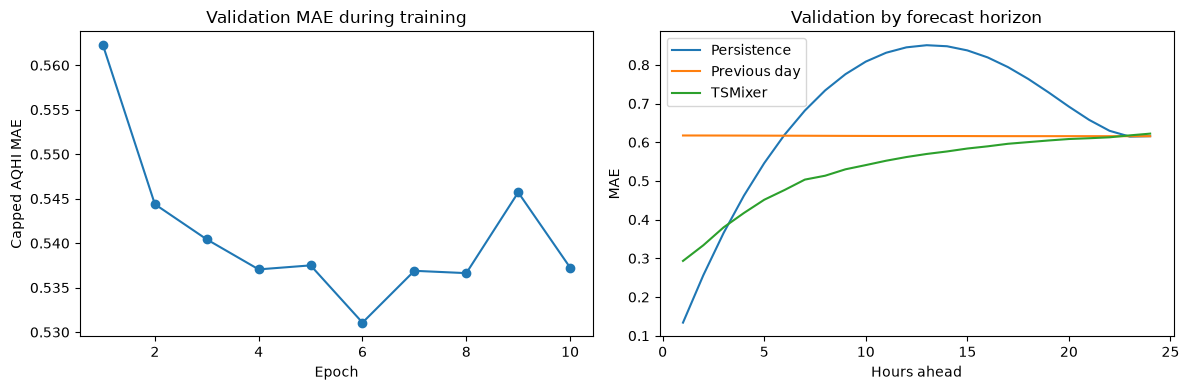

模型权重、标准化参数、训练日志、验证结果已保存： C:\Users\hxq08259\Desktop\sem1\Math7005\data\processed\tsmixer\20261111_010719_491327


In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(training_log.epoch,training_log.validation_MAE,marker='o')
axes[0].set(title='Validation MAE during training',xlabel='Epoch',ylabel='Capped AQHI MAE')
hz=pd.DataFrame(horizon_rows)
for name,g in hz.groupby('model'):axes[1].plot(g.horizon,g.MAE,label=name)
axes[1].set(title='Validation by forecast horizon',xlabel='Hours ahead',ylabel='MAE');axes[1].legend()
fig.tight_layout();fig.savefig(OUT/'training_and_validation.png',dpi=150);plt.show()
for name,t in {'comparison_validation':results,'subset_validation':pd.DataFrame(detail),
 'station_validation':pd.DataFrame(station_rows),'horizon_validation':hz}.items():
    t.to_csv(OUT/f'{name}.csv',index=False,encoding='utf-8-sig')
config={'source':str(SOURCE),'stations':STATIONS,'lookback':L,'horizon':H,'seed':SEED,
 'blocks':2,'hidden':32,'dropout':.1,'normalization':'LayerNorm over time and feature dimensions',
 'learning_rate':.001,'batch_size':256,'max_epochs':MAX_EPOCHS,'patience':PATIENCE,
 'best_epoch':best_epoch,'torch_version':str(torch.__version__),'device':str(device),
 'train_end':str(train_end),'validation_end':str(val_end),'test_evaluated':False,
 'target':'capped AQHI; 10+ encoded as 10','output_clipping':False,
 'outside_range_fraction':outside,'validation_windows':len(origins),
 'architecture_reference':'https://github.com/google-research/google-research/blob/master/tsmixer/tsmixer_basic/models/tsmixer.py'}
(OUT/'model_config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
print('模型权重、标准化参数、训练日志、验证结果已保存：',OUT)